# 00 - Revisión del dataset sintético de formas

In [4]:
import json
from pathlib import Path
import numpy as np

root = Path("../data/processed/shapes_v1")
manifest = json.loads((root / "manifest.json").read_text())
splits = ["train", "val", "test_iid", "test_comp"]
data = {s: np.load(root / f"{s}.npz") for s in splits}

print(manifest["counts"])
d = data["train"]
for k in d.files:
    print(f"{k:10s} {d[k].shape}  {d[k].dtype}")
print(d["captions"][:3])

{'train': 200000, 'val': 5000, 'test_iid': 5000, 'test_comp': 10000}
images     (200000, 16, 16)  uint8
n_obj      (200000,)  uint8
color      (200000, 2)  int8
shape      (200000, 2)  int8
size       (200000, 2)  int8
pos        (200000,)  int8
rel        (200000,)  int8
jitter     (200000, 2, 2)  int8
captions   (200000,)  <U56
['a large cyan triangle above a small white square'
 'a small orange cross right of a small orange square'
 'a large white cross above a small cyan circle']


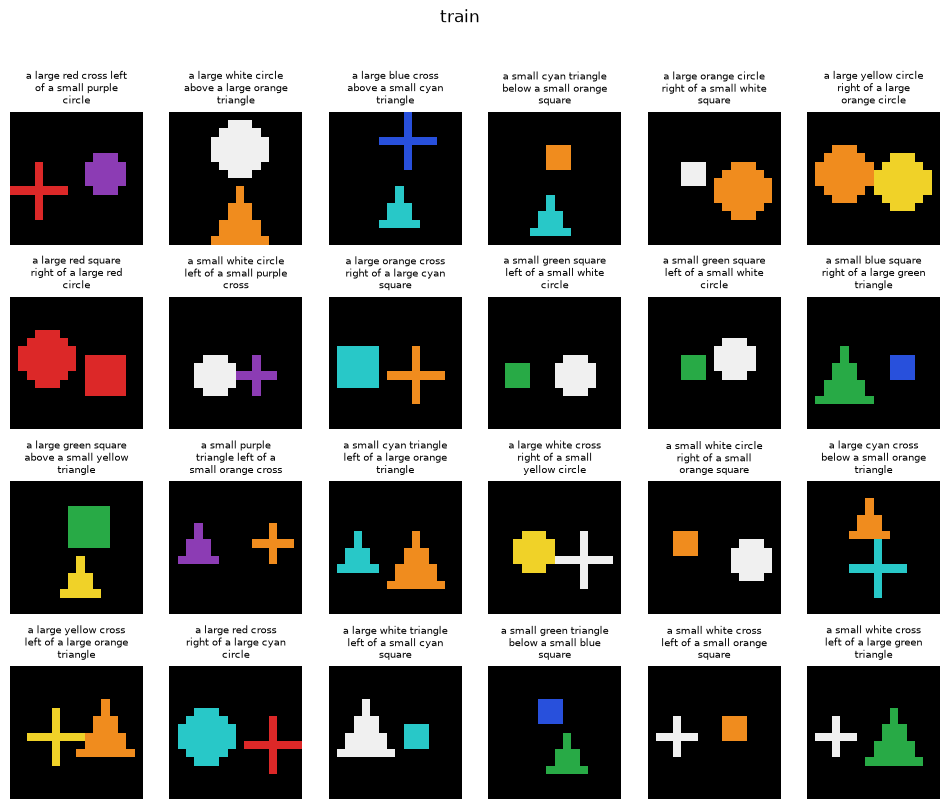

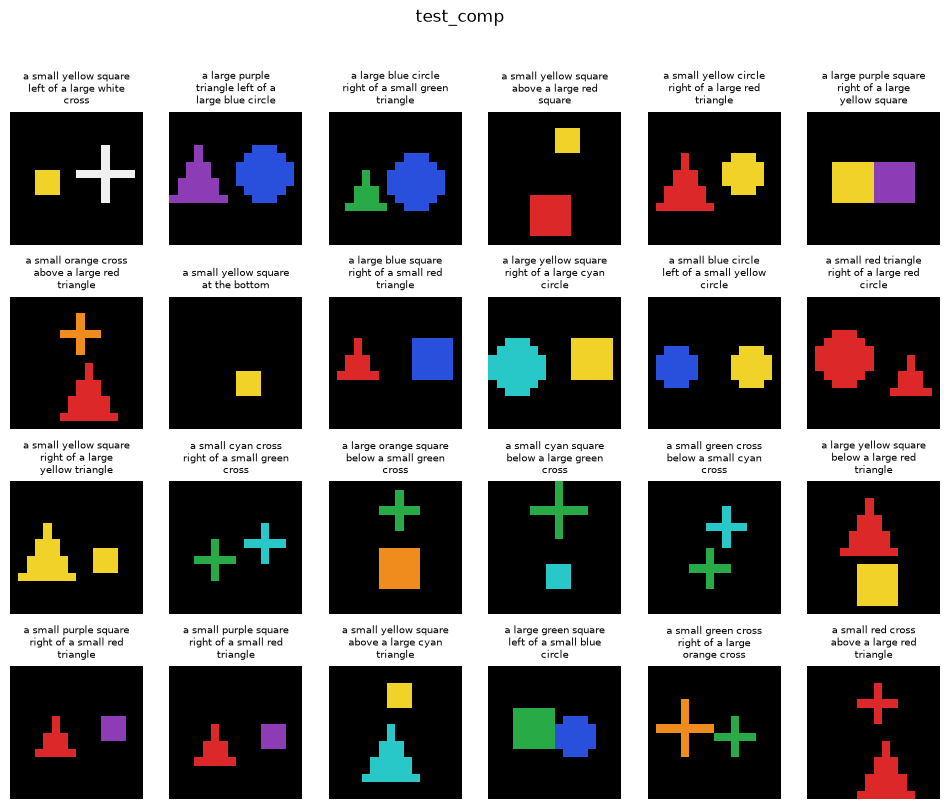

In [6]:
import matplotlib.pyplot as plt
import textwrap


palette = np.array(manifest["palette_rgb"], dtype=np.uint8)   # índice -> color RGB

def show_grid(split, n=24, cols=6, seed=0):
    d = data[split]
    idx = np.random.default_rng(seed).choice(len(d["captions"]), n, replace=False)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.3))
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(palette[d["images"][i]], interpolation="nearest")
        ax.set_title(textwrap.fill(d["captions"][i], 22), fontsize=7)
        ax.axis("off")
    fig.suptitle(split)
    plt.show()

show_grid("train")
show_grid("test_comp")

In [8]:
from scipy.ndimage import label

eight = np.ones((3, 3), dtype=int)
d = data["train"]
two = np.where(d["n_obj"] == 2)[0][:20000]
imgs = d["images"][two]
touching = np.array([label(im > 0, structure=eight)[1] == 1 for im in imgs])
same_color = d["color"][two, 0] == d["color"][two, 1]

print("pegados:", touching.mean())
print("pegados y mismo color:", (touching & same_color).mean())

pegados: 0.17295
pegados y mismo color: 0.01825


In [27]:
d = data["train"]
np.bincount(d["n_obj"])            # [0, 2016, 197984]
(d["n_obj"] == 1).sum() * 100 / (d["n_obj"] == 2).sum()

np.float64(1.0182641021496686)

In [28]:
c = d["color"]
c = c.ravel()
c = c[ c >= 0 ]
counts = np.bincount(c)

color_names = manifest["config"]["colors"]
for name, n in zip(color_names, counts):
    print(f"{name:8s} {n}")

red      42731
blue     42985
green    42639
yellow   42332
purple   56398
orange   56877
white    56761
cyan     57261


In [29]:
d = data["val"]
np.bincount(d["n_obj"])            # [0, 2016, 197984]
(d["n_obj"] == 1).sum() * 100 / (d["n_obj"] == 2).sum()

np.float64(5.307497893850043)

In [30]:
c = d["color"]
c = c.ravel()
c = c[ c >= 0 ]
counts = np.bincount(c)

color_names = manifest["config"]["colors"]
for name, n in zip(color_names, counts):
    print(f"{name:8s} {n}")

red      1032
blue     1058
green    1071
yellow   1053
purple   1356
orange   1376
white    1367
cyan     1435


In [31]:
d = data["test_iid"]
np.bincount(d["n_obj"])            # [0, 2016, 197984]
(d["n_obj"] == 1).sum() * 100 / (d["n_obj"] == 2).sum()

np.float64(5.307497893850043)

In [32]:
c = d["color"]
c = c.ravel()
c = c[ c >= 0 ]
counts = np.bincount(c)

color_names = manifest["config"]["colors"]
for name, n in zip(color_names, counts):
    print(f"{name:8s} {n}")

red      1012
blue     1057
green    1077
yellow   1086
purple   1389
orange   1371
white    1415
cyan     1341


In [33]:
d = data["test_comp"]
np.bincount(d["n_obj"])            # [0, 2016, 197984]
(d["n_obj"] == 1).sum() * 100 / (d["n_obj"] == 2).sum()

np.float64(3.7344398340248963)

In [34]:
c = d["color"]
c = c.ravel()
c = c[ c >= 0 ]
counts = np.bincount(c)

color_names = manifest["config"]["colors"]
for name, n in zip(color_names, counts):
    print(f"{name:8s} {n}")

red      3669
blue     3463
green    3625
yellow   3709
purple   1255
orange   1326
white    1282
cyan     1311


In [35]:
color_names = manifest["config"]["colors"]
shape_names = manifest["config"]["shapes"]

def pair_counts(d):
    c, s = d["color"].ravel(), d["shape"].ravel()
    ok = c >= 0                                   # quita los objetos inexistentes
    table = np.zeros((len(color_names), len(shape_names)), dtype=int)
    np.add.at(table, (c[ok], s[ok]), 1)           # suma 1 en la celda (color, forma)
    return table

import pandas as pd
for split in splits:
    print(split)
    print(pd.DataFrame(pair_counts(data[split]), index=color_names, columns=shape_names))

train
        circle  square  triangle  cross
red      13803   14666         0  14262
blue         0   14632     14080  14273
green    13645   14793     14201      0
yellow   13858       0     14306  14168
purple   13506   14728     14100  14064
orange   13644   14863     14272  14098
white    13667   14654     14207  14233
cyan     13695   14933     14266  14367
val
        circle  square  triangle  cross
red        314     373         0    345
blue         0     374       335    349
green      349     378       344      0
yellow     347       0       341    365
purple     339     338       352    327
orange     343     343       343    347
white      337     342       349    339
cyan       344     378       352    361
test_iid
        circle  square  triangle  cross
red        324     367         0    321
blue         0     343       349    365
green      357     375       345      0
yellow     384       0       346    356
purple     318     366       359    346
orange     345     37

(np.float64(-0.5), np.float64(15.5), np.float64(15.5), np.float64(-0.5))

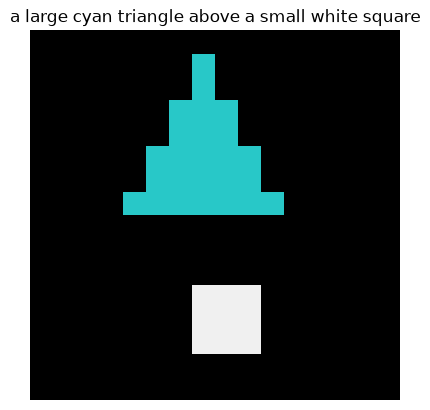

In [41]:
d = data["train"]

d["captions"][:5]
d["captions"][0]
len(d["captions"])

i = 0
plt.imshow(palette[d["images"][i]], interpolation="nearest")
plt.title(d["captions"][i])
plt.axis("off")

In [42]:
words = d["captions"][0].split()
len(words)

9

In [43]:
d["captions"][d["n_obj"] == 1][:5]

array(['a small green circle at the bottom',
       'a large cyan square on the left',
       'a small white circle on the right',
       'a small red cross in the center',
       'a large green circle on the left'], dtype='<U56')

In [44]:
d["captions"][d["n_obj"] == 2][:5]

array(['a large cyan triangle above a small white square',
       'a small orange cross right of a small orange square',
       'a large white cross above a small cyan circle',
       'a large orange cross above a large red cross',
       'a small white circle below a small orange square'], dtype='<U56')